In [13]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from src import config
from src.preprocessing import stratified_sample

df = pd.read_csv(config.CLEANED_PATH)
print(df.shape)

NUM_FEATURES = ["revenue_log", "dti_n", "loan_amnt", "fico_n", "emp_length_years"]
sample_idx = stratified_sample(df).index   # 20k rows for the slow steps

(1347681, 17)


In [14]:
scaler_num = StandardScaler()
X_num = scaler_num.fit_transform(df[NUM_FEATURES])
print("Scaled matrix:", X_num.shape)

Scaled matrix: (1347681, 5)


[0.323 0.539 0.727 0.913 1.   ]


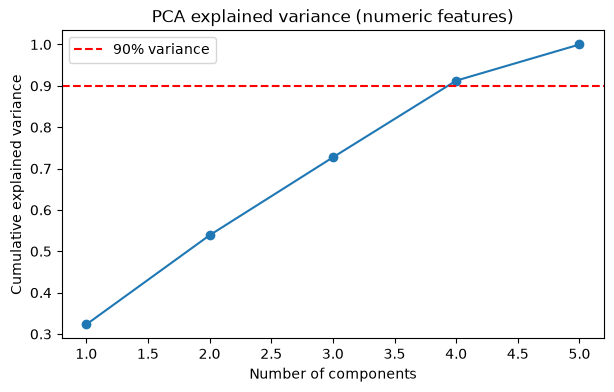

Components for 90% variance: 4


In [15]:
pca_full = PCA(random_state=config.RANDOM_STATE).fit(X_num)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
print(cum_var.round(3))

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker="o")
plt.axhline(0.90, color="red", linestyle="--", label="90% variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA explained variance (numeric features)")
plt.legend()
plt.savefig(config.FIGURES_DIR / "pca_variance_numeric.png", dpi=150)
plt.show()

N_COMP = int(np.argmax(cum_var >= 0.90) + 1)
print("Components for 90% variance:", N_COMP)

In [16]:
pca_num = PCA(n_components=N_COMP, random_state=config.RANDOM_STATE)
X_pca_num = pca_num.fit_transform(X_num)
print("Explained variance kept:", round(pca_num.explained_variance_ratio_.sum(), 3))

Explained variance kept: 0.913


2 0.2184
3 0.1999
4 0.2166
5 0.2114
6 0.2154
7 0.205
8 0.2027


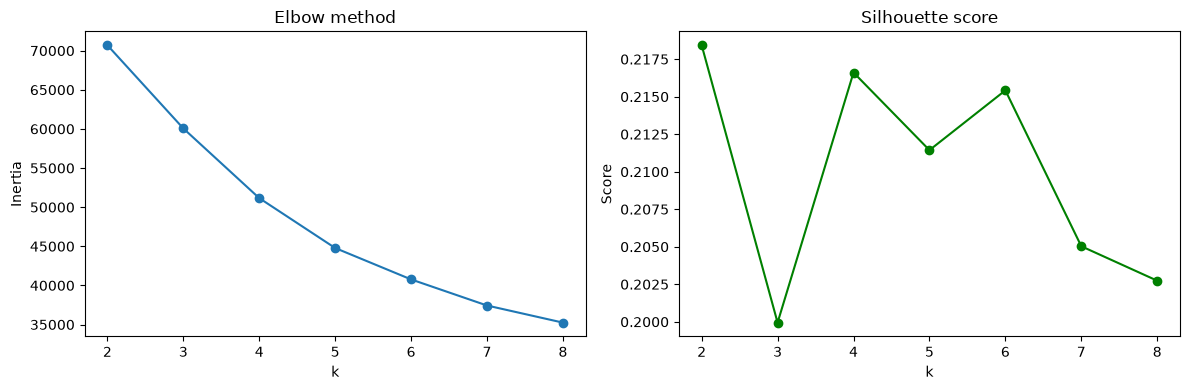

In [17]:
X_s = X_pca_num[df.index.get_indexer(sample_idx)]
k_range = range(2, 9)
inertias, sil_scores = [], []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=config.RANDOM_STATE)
    labels = km.fit_predict(X_s)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_s, labels))
    print(k, round(sil_scores[-1], 4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_range, inertias, marker="o")
axes[0].set(title="Elbow method", xlabel="k", ylabel="Inertia")
axes[1].plot(k_range, sil_scores, marker="o", color="green")
axes[1].set(title="Silhouette score", xlabel="k", ylabel="Score")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "kmeans_k_selection_numeric.png", dpi=150)
plt.show()

In [18]:
BEST_K = 4   # change this after looking at Cell 5

kmeans_num = KMeans(n_clusters=BEST_K, n_init=10, random_state=config.RANDOM_STATE)
df["kmeans_cluster"] = kmeans_num.fit_predict(X_pca_num)

print(df["kmeans_cluster"].value_counts().sort_index())


kmeans_cluster
0    429593
1    445576
2    301605
3    170907
Name: count, dtype: int64


In [19]:
profile = df.groupby("kmeans_cluster")[NUM_FEATURES + ["revenue"]].mean().round(1)
profile["size"] = df["kmeans_cluster"].value_counts().sort_index()
profile["default_rate"] = df.groupby("kmeans_cluster")["Default"].mean().round(3)
print(profile)

print(pd.crosstab(df["kmeans_cluster"], df["purpose_grouped"], normalize="index").round(2))
print(pd.crosstab(df["kmeans_cluster"], df["home_ownership_n"], normalize="index").round(2))

                revenue_log  dti_n  loan_amnt  fico_n  emp_length_years  \
kmeans_cluster                                                            
0                      11.0   19.6    11652.8   686.5               9.2   
1                      10.8   18.8     9652.3   686.8               2.7   
2                      11.7   17.3    25884.5   697.1               6.1   
3                      11.2   14.4    13481.2   759.0               6.1   

                 revenue    size  default_rate  
kmeans_cluster                                  
0                65554.4  429593         0.211  
1                52142.3  445576         0.220  
2               123848.9  301605         0.213  
3                78111.1  170907         0.096  
purpose_grouped   car  credit_card  debt_consolidation  home_improvement  \
kmeans_cluster                                                             
0                0.01         0.21                0.60              0.07   
1                0.01      

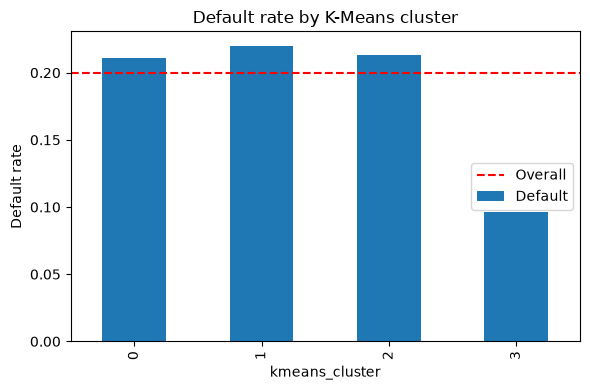

In [20]:
default_by_cluster = df.groupby("kmeans_cluster")["Default"].mean()
default_by_cluster.plot(kind="bar", figsize=(6, 4), title="Default rate by K-Means cluster")
plt.ylabel("Default rate")
plt.axhline(df["Default"].mean(), color="red", linestyle="--", label="Overall")
plt.legend()
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "default_by_cluster.png", dpi=150)
plt.show()

In [21]:
config.MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(scaler_num, config.MODELS_DIR / "scaler_num.pkl")
joblib.dump(pca_num, config.MODELS_DIR / "pca_num.pkl")
joblib.dump(kmeans_num, config.MODELS_DIR / "kmeans_num.pkl")
np.save(config.PROCESSED_DIR / "X_pca_num.npy", X_pca_num)
df.to_csv(config.PROCESSED_DIR / "clustered_loans.csv", index=False)
print("Saved")

Saved
